# 02. 처프 신호
목표: 시간에 따라 주파수가 변하는 신호를 푸리에 변환으로 분석하면 무엇을 놓치는지 확인한다.

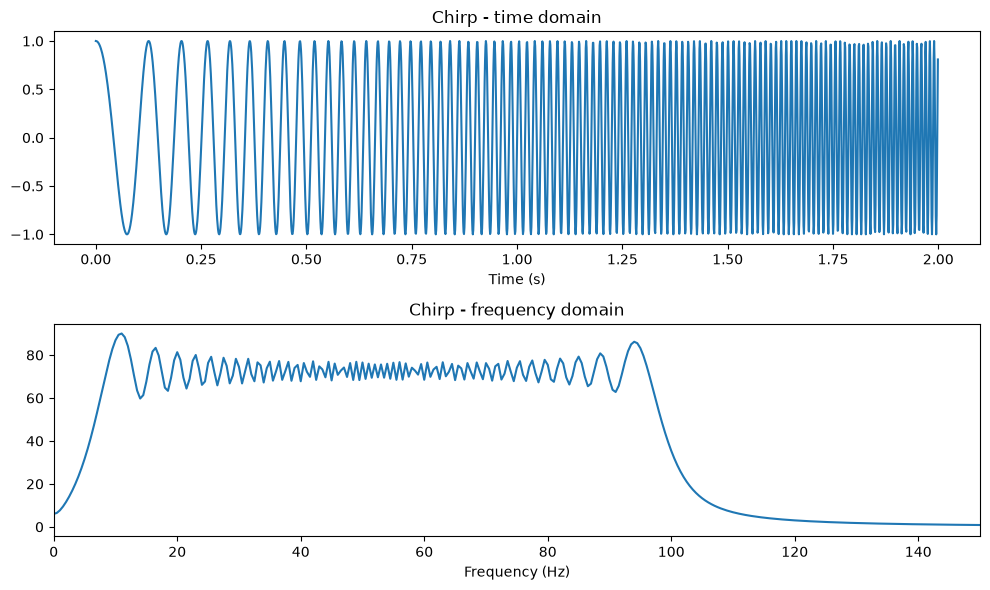

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import chirp

fs = 1000
t = np.arange(0, 2, 1/fs)

x = chirp(t, f0=5, t1=2, f1=100, method='linear')

spectrum = np.abs(np.fft.rfft(x))
freqs = np.fft.rfftfreq(len(x), 1/fs)

fig, ax = plt.subplots(2, 1, figsize=(10, 6))

ax[0].plot(t, x)
ax[0].set_title('Chirp - time domain')
ax[0].set_xlabel('Time (s)')

ax[1].plot(freqs, spectrum)
ax[1].set_title('Chirp - frequency domain')
ax[1].set_xlabel('Frequency (Hz)')
ax[1].set_xlim(0, 150)

plt.tight_layout()
plt.show()

## 실험 1 관찰
- 시간 영역: 오른쪽으로 갈수록 파동이 촘촘해짐 -> 주파수가 올라감
- 주파수 영역: 5~100Hz가 넓은 띠로 나옴 (양끝이 높은 이유는 스펙트럼 누설)
- 알 수 없는 것: 5Hz가 처음에 있었는지 끝에 있었는지

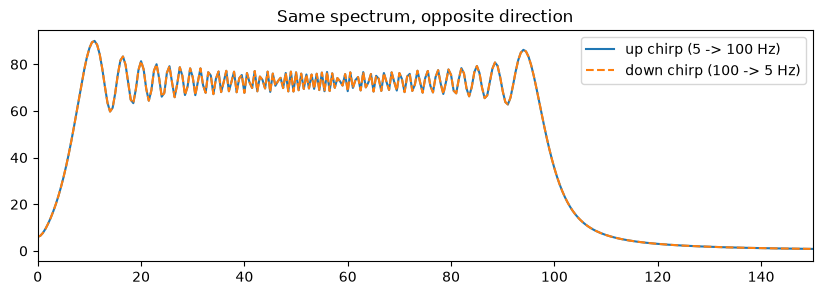

In [8]:
# 100Hz에서 시작해 5Hz로 내려가는 처프
x_down = chirp(t, f0=100, t1=2, f1=5, method='linear')
spectrum_down = np.abs(np.fft.rfft(x_down))

plt.figure(figsize=(10, 3))
plt.plot(freqs, spectrum, label="up chirp (5 -> 100 Hz)")
plt.plot(freqs, spectrum_down, label="down chirp (100 -> 5 Hz)", linestyle="--")
plt.xlim(0, 150)
plt.legend()
plt.title("Same spectrum, opposite direction")
plt.show()

## 실험 2 관찰
- 푸리에 변환은 올라가는 소리와 내려가는 소리를 구분하지 못함
- 귀로는 구분 가능
- 이 때문에 스펙트로그램이 필요

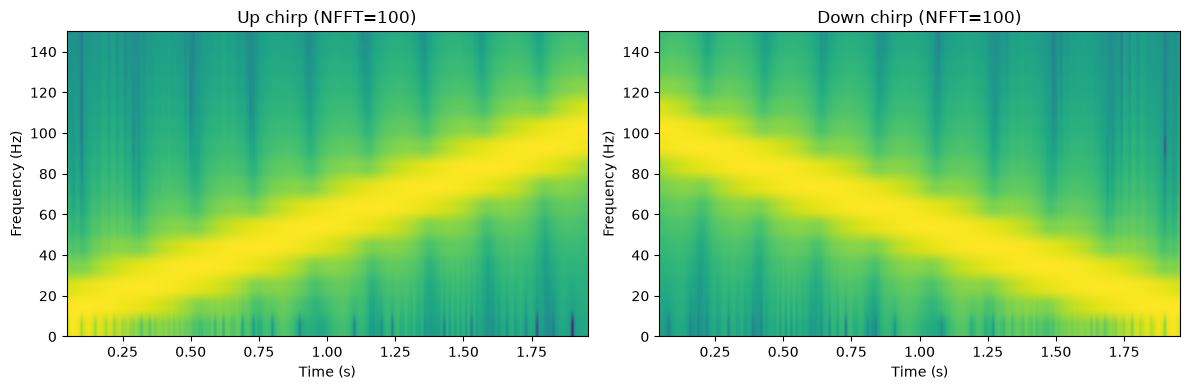

In [31]:
NFFT = 100
noverlap = int(NFFT * 0.9)    # 조각 길이의 90%만큼 겹치기

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].specgram(x, NFFT=NFFT, Fs=fs, noverlap=noverlap)
ax[0].set_title(f"Up chirp (NFFT={NFFT})")
ax[1].specgram(x_down, NFFT=NFFT, Fs=fs, noverlap=noverlap)
ax[1].set_title(f"Down chirp (NFFT={NFFT})")
for a in ax:
    a.set_xlabel("Time (s)")
    a.set_ylabel("Frequency (Hz)")
    a.set_ylim(0, 150)
plt.tight_layout()
plt.show()

## 실험 3 관찰
- NFFT=32: 처프 선이 세로로 매우 두껍다
- NFFT=512: 처프 선이 세로로 약간 두껍다 (32보다는 훨씬 얇다)
- 시간축 위치는 NFFT가 작을수록 더 정확해 보인다

## 실험 3 해석
- NFFT가 클 때: 조각 하나가 길어서, 그 조각 안에서도 처프의 주파수가 많이 변한다.
  조각 안에 여러 주파수가 실제로 다 들어 있으니 FFT가 그걸 띠로 표시하고, 선이 세로로 두꺼워진다. (실험 1의 5~100Hz 띠와 같은 원리)
- NFFT가 작을 때: 칸(주파수 빈) 사이 간격이 넓다. NFFT=32면 칸이 0, 31.25, 62.5Hz… 간격으로만 있어서,
  약 31Hz보다 가까운 주파수끼리는 구별되지 않는다. 처프가 실제로는 가는 선이어도 최소 칸 하나 두께로 그려진다.
- 구분할 수 있는 최소 주파수 간격 ≈ 1 / 보는 시간
- Hann 창의 영향: specgram은 기본으로 Hann 창을 씌워 조각 양 끝을 0으로 줄인다. 실제로 보는 시간이 짧아지는 셈이다.
  - NFFT=512: 조각 안에서 처프가 변하는 폭이 줄어든 것처럼 보여 덜 두껍다
  - NFFT=32: 최소 간격이 더 커져서 31Hz보다 더 두껍게 나온다

## 결론
- 스펙트로그램은 어떤 NFFT를 골라도 처프를 완벽하게 가는 선으로 그릴 수 없다 (시간-주파수 트레이드오프)
- 이 한계 때문에 TFDR 논문은 스펙트로그램 대신 위그너 분포를 쓴다 → 03에서 확인

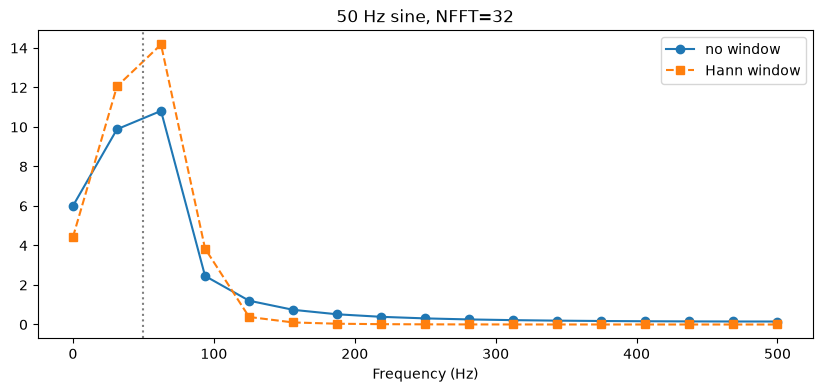

In [32]:
N = 32
t_short = np.arange(N) / fs
s = np.sin(2*np.pi*50*t_short)          # 50Hz 사인파, 측정값 32개
f = np.fft.rfftfreq(N, 1/fs)

plain = np.abs(np.fft.rfft(s))
hann = np.abs(np.fft.rfft(s * np.hanning(N))) * 2   # 창 때문에 줄어든 크기 보정

plt.figure(figsize=(10, 4))
plt.plot(f, plain, "o-", label="no window")
plt.plot(f, hann, "s--", label="Hann window")
plt.axvline(50, color="gray", linestyle=":")
plt.xlabel("Frequency (Hz)")
plt.legend()
plt.title("50 Hz sine, NFFT=32")
plt.show()